**Introduction**

Today, various FinBERT models still form the basis of risk management in the financial sector, where there is a residual question - is small really beautiful (Kim et al., 2024) Phi is pushing the boundaries of making large language models small as well as powerful, filling the gap that still exists between accuracy of newer LLMs and inference speed and low cost of open-access models. Therefore these models were researched to determine where the niche in the financial market was for our proposed agentic approach with Claude.

**Approach**

JPMorgan (JPM) was used as a financially stable example, but with some hurdles that were managed well by the bank in the quarters analysed. Here, the approach developed in Market Research_Part 1 underwent a stress test on Credit Suisse (CS) data approaching its collapse (Market Research_Part 2).

**Details of approach**

For details of the approach used, including preprocessing, please see Market Research_Part 1a.

**Installs**

In [ ]:
# Install numpy first to avoid ABI mismatches
!pip install numpy==1.26.4

# Reinstall other core packages safely
!pip install scipy
!pip install gensim
!pip install pyldavis
!pip install pymupdf

# Install compatible torch + torchvision (CPU version to avoid CUDA mismatches)
!pip install torch==2.2.2 torchvision==0.17.2 --index-url https://download.pytorch.org/whl/cpu

# Install BERTopic stack
!pip install transformers==4.40.2 accelerate==0.27.2 sentence-transformers==2.5.1
!pip install bertopic==0.16.4

Looking in indexes: https://download.pytorch.org/whl/cpu


**Library Imports**

In [ ]:
import matplotlib.pyplot as plt
import spacy
import fitz
import os
import re
import nltk
import gdown
import numpy as np
import pandas as pd
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download("wordnet")

from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import string
import re

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import pipeline

from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from bertopic.vectorizers import ClassTfidfTransformer
from hdbscan import HDBSCAN
from tqdm import tqdm
from nltk.corpus import stopwords
import torch as torch

from gensim.models import LdaModel
from gensim.corpora import Dictionary
import nltk
import gensim
import pyLDAvis.gensim_models as gensimvis
import pyLDAvis
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk
nltk.download('vader_lexicon')
from collections import Counter

from transformers import AutoModelForCausalLM, AutoTokenizer, pipeline
import json

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


**Downloads Q1 2021-Q4 2022**

The quarters used were those in the lead up to the CS collapse in Q1 2023.

In [ ]:
# List of shared Google Drive links (use shareable links)
drive_links = ["https://drive.google.com/file/d/10TFiE2fsUQFKGHL2GipqAdvZ2U541Sv0/view?usp=sharing",
               "https://drive.google.com/file/d/10d041Pzo6QFfkzklB68sNT1NQRjvHUTk/view?usp=sharing",
               "https://drive.google.com/file/d/1BFtyzRMCGyhVvBdX0Ba5ydI6AJdfW93S/view?usp=sharing",
               "https://drive.google.com/file/d/1BmmY_N6KhTWC3b_q6mgfCb9gxJQ2BhNB/view?usp=sharing",
               "https://drive.google.com/file/d/1EG8bDrOpE1Lg4EHR-YcSE392AqqiKNH-/view?usp=sharing",
               "https://drive.google.com/file/d/1KcSf9P-qZmaPAGNtZAMJOkNmN8_UJ8kr/view?usp=sharing",
               "https://drive.google.com/file/d/1MyMiRBCo66WymEuCSpoOxV9wnP2NOMwP/view?usp=sharing",
               "https://drive.google.com/file/d/1S2buxLVy4g0jh4XVGHJSOKT6P5trr70T/view?usp=sharing",
               "https://drive.google.com/file/d/1TIBumVP4gScLzv2_2pVgXc68NRRgn4Uo/view?usp=sharing",
               "https://drive.google.com/file/d/1TN2MQCYjcHspc3VA9MWzvBx9qvL6atpq/view?usp=sharing",
               "https://drive.google.com/file/d/1Tl0Y7xH3l-ZaLOt1L-j7ddmqGE7NsrBl/view?usp=sharing",
               "https://drive.google.com/file/d/1TxkeZWtLMLankjduoESp4o9UnQ19mQ7h/view?usp=sharing",
               "https://drive.google.com/file/d/1VPabex7Be8FitL0uy6qf58Tiqgnx6RmG/view?usp=sharing",
               "https://drive.google.com/file/d/1Ynw_s6gpbA06owpVDoF3nmCRzLJn6IE2/view?usp=sharing",
               "https://drive.google.com/file/d/1b5o-sOiQLJHZDiUOK0_5KYdXsaQuudFU/view?usp=sharing",
               "https://drive.google.com/file/d/1hdzNPzvNRvkjhULOkWDalBvXmAAPFPjI/view?usp=sharing",
               "https://drive.google.com/file/d/1jgpcUOc7k3P5xj8XLmUBEH8Qd565LUrv/view?usp=sharing",
               "https://drive.google.com/file/d/1kg6vP2uqoV8PBOq9O9-X0dnQvwC7tJVq/view?usp=sharing",
               "https://drive.google.com/file/d/1sZm7vybYxU-MNiz1ssLFXcS72zDIPWck/view?usp=sharing",
               "https://drive.google.com/file/d/1yIrjr576nUBTwjdCJsuazUYSk7R_z0Wr/view?usp=sharing"

]

# Output directory
download_dir = "transcripts"
os.makedirs(download_dir, exist_ok=True)

# Download from drive
def download_from_drive(url, output_path):
    try:
        gdown.download(url, output_path, fuzzy=True)
        print(f"Downloaded: {output_path}")
    except Exception as e:
        print(f"Failed to download {url}: {e}")

# Extract text from pdf
def extract_text_from_pdf(pdf_path):
    doc = fitz.open(pdf_path)
    full_text = ""
    for page in doc:
        full_text += page.get_text()
    return full_text

# Iterate through all pdfs/transcripts
all_texts = []
all_filenames = []

for i, url in enumerate(tqdm(drive_links, desc="Downloading transcripts")):
    filename = f"Transcript_{i+1}.pdf"
    output_path = os.path.join(download_dir, filename)

    # Download the PDF
    download_from_drive(url, output_path)

    # Verify and extract
    if os.path.exists(output_path):
        print(f"Size: {os.path.getsize(output_path)} bytes")

        text = extract_text_from_pdf(output_path)
        all_texts.append(text)
        all_filenames.append(filename)

        print("Text preview:", text[:500], "\n" + "-"*80)

From: https://drive.google.com/uc?id=10TFiE2fsUQFKGHL2GipqAdvZ2U541Sv0
To: /content/transcripts/Transcript_1.pdf

100%|██████████| 1.18M/1.18M [00:00<00:00, 149MB/s]


Downloaded: transcripts/Transcript_1.pdf
Size: 1175397 bytes


Text preview:  
 
 
Earnings
Release 
4Q21 
 
                 
  
  
  
  
  
  
  
  
 
  
  
  
  
  
  
  
  
 
  
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
  
  
  
  
  
  
  
  
 
  
  
  
  
  
  
  
  
 
  
  
  
  
  
  
  
  
 
  
  
  
  
  
  
  
  
 
  
  
  
  
  
  
  
  
 
  
  
  
  
  
  
  
  
 
  
  
  
  
  
  
  
  
 
  
  
  
  
  
  
  
  
 
  
  
  
  
  
  
  
  
 
  
  
  
  
  
  
  
  
 
  
  
  
  
  
  
  
  
 
  
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
  
  
  
  
  
  
  
  
 
  
  
  
  
  
  
   
--------------------------------------------------------------------------------


Downloading...
From: https://drive.google.com/uc?id=10d041Pzo6QFfkzklB68sNT1NQRjvHUTk
To: /content/transcripts/Transcript_2.pdf

100%|██████████| 1.96M/1.96M [00:00<00:00, 119MB/s]

Downloaded: transcripts/Transcript_2.pdf
Size: 1963692 bytes
Text preview: Credit Suisse 
Second Quarter 2021 Results 
Analyst and Investor Call 
Thomas Gottstein, Chief Executive Officer 
David Mathers, Chief Financial Officer 
July 29, 2021 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
  
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
  
 
 
 
 
 
 
 
 
 
 
 
 
 
 
Disclaimer (1/2) 
This material does not purport to contain all of the information that you may wish to consi 
--------------------------------------------------------------------------------


...

Downloading...
From: https://drive.google.com/uc?id=1sZm7vybYxU-MNiz1ssLFXcS72zDIPWck
To: /content/transcripts/Transcript_19.pdf

100%|██████████| 353k/353k [00:00<00:00, 107MB/s]

Downloaded: transcripts/Transcript_19.pdf
Size: 352659 bytes
Text preview:  
 
 
Credit Suisse (Schweiz) AG 
Financial 
Report 
6M21 
 
 
 
 
 
 
  
 
 
 
 
 
 
 
 
Financial Report 6M21 
Credit Suisse (Schweiz) AG 
2 
Report on the Financial 
Statements 
3  
Interim financial statements 
– unaudited 
6  
Notes to the interim financial 
statements – unaudited 
Capital adequacy disclosures for Credit Suisse Group AG and Credit Suisse (Schweiz) AG are presented in the publications “Pillar 3 and regulatory disclo­
sures – Credit Suisse Group AG” and “Regulatory disclosure 
--------------------------------------------------------------------------------


Downloading...
From: https://drive.google.com/uc?id=1yIrjr576nUBTwjdCJsuazUYSk7R_z0Wr
To: /content/transcripts/Transcript_20.pdf

100%|██████████| 734k/734k [00:00<00:00, 134MB/s]


Downloaded: transcripts/Transcript_20.pdf
Size: 733531 bytes


Text preview: Credit Suisse (Bank)
Financial Statements  
6M22
﻿
﻿
Notes to the condensed consolidated financial statements 
– unaudited
1  Summary of significant accounting policies................................................................................9
2  Recently issued accounting standards.......................................................................................9
3  Business developments and subsequent events.........................................................................9
4 
--------------------------------------------------------------------------------


**DataFrame**

In [ ]:
# Produce a DataFrame with all transcripts - "Transcript 1" and "text"
CS_df = pd.DataFrame({"filename": all_filenames, "text": all_texts})
CS_df

,filename,text
0,Transcript_1.pdf,\n \n \nEarnings\nRelease \n4Q21 \n \n ...
1,Transcript_2.pdf,Credit Suisse \nSecond Quarter 2021 Results \n...
2,Transcript_3.pdf,\nFinancial \nReport\n3Q21\n﻿\n﻿\n﻿\nKey metr...
3,Transcript_4.pdf,"November 4, 2021\nCredit Suisse\nThird Quarter..."
4,Transcript_5.pdf,\nFinancial \nReport\n1Q21\n﻿\n﻿\n﻿\nKey metr...
5,Transcript_6.pdf,Financial Report \n3Q22\n﻿\n﻿\n﻿\nKey metrics ...
6,Transcript_7.pdf,2Q22 Results\nAnalyst and Investor Call\nThoma...
7,Transcript_8.pdf,Earnings Release \n4Q22\n﻿\n﻿\n2\n﻿\nKey metr...
8,Transcript_9.pdf,1Q22 Results\nAnalyst and Investor Call\nThoma...
9,Transcript_10.pdf,"Thomas Gottstein, Chief Executive Officer\nDav..."


**Preprocessing**

**a. Generate columns**

In [ ]:
# Load spaCy model
nlp = spacy.load("en_core_web_sm")

In [ ]:
# Set nlp max length
nlp.max_length = 3000000

# From text produce third column "text preview" taking the first two sentences
def get_first_two_sentences(text):
    doc = nlp(text)  # Use the loaded spaCy model from earlier
    sentences = [sent.text.strip() for sent in doc.sents]
    return " ".join(sentences[:2])

CS_df["text_preview"] = CS_df["text"].apply(get_first_two_sentences)
CS_df

,filename,text,text_preview
0,Transcript_1.pdf,\n \n \nEarnings\nRelease \n4Q21 \n \n ...,Earnings\nRelease \n4Q21 \n \n ...
1,Transcript_2.pdf,Credit Suisse \nSecond Quarter 2021 Results \n...,Credit Suisse \nSecond Quarter 2021 Results \n...
2,Transcript_3.pdf,\nFinancial \nReport\n3Q21\n﻿\n﻿\n﻿\nKey metr...,Financial \nReport\n3Q21\n﻿\n﻿\n﻿\nKey metrics...
3,Transcript_4.pdf,"November 4, 2021\nCredit Suisse\nThird Quarter...","November 4, 2021\nCredit Suisse\nThird Quarter..."
4,Transcript_5.pdf,\nFinancial \nReport\n1Q21\n﻿\n﻿\n﻿\nKey metr...,Financial \nReport\n1Q21\n﻿\n﻿\n﻿\nKey metrics...
5,Transcript_6.pdf,Financial Report \n3Q22\n﻿\n﻿\n﻿\nKey metrics ...,Financial Report \n3Q22\n﻿\n﻿\n﻿\nKey metrics ...
6,Transcript_7.pdf,2Q22 Results\nAnalyst and Investor Call\nThoma...,2Q22 Results\nAnalyst and Investor Call\nThoma...
7,Transcript_8.pdf,Earnings Release \n4Q22\n﻿\n﻿\n2\n﻿\nKey metr...,Earnings Release \n4Q22\n﻿\n﻿\n2\n﻿\nKey metr...
8,Transcript_9.pdf,1Q22 Results\nAnalyst and Investor Call\nThoma...,1Q22 Results\nAnalyst and Investor Call\nThoma...
9,Transcript_10.pdf,"Thomas Gottstein, Chief Executive Officer\nDav...","Thomas Gottstein, Chief Executive Officer\nDav..."


In [ ]:
# Turn text column into year, quarter, document type
# Sample function to extract quarter, year, and document type
def extract_info(text):
    text = text.replace('\n', ' ').lower()  # Normalize
    quarter = None
    year = None
    doc_type = None

    # QUARTER
    quarter_map = {
        "first quarter": "Q1", "1q": "Q1", "q1": "Q1",
        "second quarter": "Q2", "2q": "Q2", "q2": "Q2",
        "third quarter": "Q3", "3q": "Q3", "q3": "Q3",
        "fourth quarter": "Q4", "4q": "Q4", "q4": "Q4"
    }

    for key, value in quarter_map.items():
        if re.search(rf'\b{key}\b', text):
            quarter = value
            break

    # YEAR (look for 4-digit year or 2-digit near a Q)
    year_match = re.search(r'(20\d{2})', text)
    if year_match:
        year = year_match.group(1)
    else:
        # Fallback: try to extract from 1Q21 style
        match_2digit = re.search(r'[1-4]q(\d{2})', text)
        if match_2digit:
            year = "20" + match_2digit.group(1)

    # DOCUMENT TYPE
    if "earnings release" in text:
        doc_type = "Earnings Release"
    elif "financial report" in text:
        doc_type = "Financial Report"
    elif "analyst and investor call" in text or "earnings call" in text:
        doc_type = "Earnings Call"
    elif "financial statements" in text:
        doc_type = "Financial Statements"
    elif "annual report" in text:
        doc_type = "Annual Report"

    return pd.Series([quarter, year, doc_type])

# Assuming df is your DataFrame with a 'text' column
CS_df[['quarter', 'year', 'document_type']] = CS_df['text'].apply(extract_info)

In [ ]:
# Drop filename and text preview
CS_df = CS_df.drop(columns=["filename", "text_preview"])

# Show DataFrame
CS_df.head()

,text,quarter,year,document_type
0,\n \n \nEarnings\nRelease \n4Q21 \n \n ...,Q1,2021,Earnings Release
1,Credit Suisse \nSecond Quarter 2021 Results \n...,Q1,2021,Financial Report
2,\nFinancial \nReport\n3Q21\n﻿\n﻿\n﻿\nKey metr...,Q1,2021,Financial Report
3,"November 4, 2021\nCredit Suisse\nThird Quarter...",Q3,2021,None
4,\nFinancial \nReport\n1Q21\n﻿\n﻿\n﻿\nKey metr...,Q1,2021,Financial Report


In [ ]:
CS_df.tail()

,text,quarter,year,document_type
15,3Q22 Results\nAnalyst and Investor Call\nUlric...,None,2022,Earnings Release
16,Annual Report \n2021\nCredit Suisse Group AG ...,Q1,2021,Earnings Release
17,\nFinancial \nReport\n2Q21\n﻿\n﻿\n﻿\nKey metr...,Q2,2021,Financial Report
18,\n \n \nCredit Suisse (Schweiz) AG \nFinancia...,None,2021,Financial Report
19,Credit Suisse (Bank)\nFinancial Statements \n...,None,2022,Financial Report




**b. Convert into sentences**

In [ ]:
# Container for all sentence data
sentence_data = []

# Define unwanted phrase(s)
unwanted_phrases = [
    "good morning ladies and gentlemen"
]

# Loop over rows of CS_df DataFrame
for index, row in CS_df.iterrows():
    text = row['text']

    # Clean up text - replace all whitespace (including newlines) with a single space
    clean_text = re.sub(r'\s+', ' ', text).strip()

    # Segment sentences
    doc = nlp(clean_text)
    sentences = [sent.text.strip() for sent in doc.sents]

    for s in sentences:
        # Skip unwanted phrases
        if any(phrase in s.lower() for phrase in unwanted_phrases):
            continue

        # Include all other columns from the original row except 'text'
        row_data = row.drop('text').to_dict()
        row_data['sentence'] = s

        sentence_data.append(row_data)

# Create DataFrame
CS_df_sentences = pd.DataFrame(sentence_data)

# Summary
print(f"Extracted {len(CS_df_sentences)} cleaned sentences from {len(CS_df)} documents.")
print(CS_df_sentences.head())

Extracted 26530 cleaned sentences from 20 documents.
  quarter  year     document_type  \
0      Q1  2021  Earnings Release   
1      Q1  2021  Earnings Release   
2      Q1  2021  Earnings Release   
3      Q1  2021  Earnings Release   
4      Q1  2021  Earnings Release   

                                            sentence  
0  Earnings Release 4Q21 Key metrics in / end of ...  
1  Net revenues 4,582 5,437 5,221 (16) (12) 22,69...  
2  Assets under management 1,614.0 1,623.0 1,511....  
3  Total shareholders’ equity 44,032 44,498 42,67...  
4  2 Credit Suisse In 4Q21, we recorded a net los...  


In [ ]:
# Show DataFrame tail
CS_df_sentences.tail()

,quarter,year,document_type,sentence
26525,None,2022,Financial Report,Primarily includes cash collateral on derivati...
26526,None,2022,Financial Report,﻿ ﻿ 56 Condensed consolidated financial statem...
26527,None,2022,Financial Report,Refer to “Note 32 – Assets pledged and collate...
26528,None,2022,Financial Report,Assets pledged end of 6M22 2021 CHF million To...
26529,None,2022,Financial Report,﻿ ﻿


**c. Produce Transcripts List**

In [ ]:
# Extract sentences from 'sentence' column
all_transcripts_list = CS_df_sentences['sentence'].tolist()

# Preprocessing function
def preprocess_text(text):
    text = text.lower()  # Convert to lowercase
    text = re.sub(r'\d+', '', text)  # Remove numbers
    words = word_tokenize(text)  # Tokenize text
    stop_words = set(stopwords.words('english'))  # Set of stopwords
    filtered_words = [word for word in words if word.isalnum() and word not in stop_words]  # Remove stopwords & punctuation
    return ' '.join(filtered_words)

# Apply preprocessing to all sentences
preprocessed_transcripts = [preprocess_text(sentence) for sentence in all_transcripts_list]

# Preview cleaned result
print("\nPreprocessed sentence preview:")
for i, sentence in enumerate(preprocessed_transcripts[:3]):
    print(f"Cleaned Sentence {i+1}:", sentence, "\n" + "-"*80)


Preprocessed sentence preview:
Cleaned Sentence 1: earnings release q key metrics end change end change q q q qoq yoy yoy credit suisse chf million 
--------------------------------------------------------------------------------
Cleaned Sentence 2: net revenues provision credit losses total operating expenses loss taxes net loss attributable shareholders ratio effective tax rate basic loss per share chf diluted loss per share chf return equity return tangible equity assets management net new assets chf billion 
--------------------------------------------------------------------------------
Cleaned Sentence 3: assets management net new assets balance sheet statistics chf million total assets net loans 
--------------------------------------------------------------------------------


**BERTOPIC**

In [ ]:
# Explicitly set the embedding model
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")
topic_model = BERTopic(embedding_model=embedding_model)

# Embed the documents
embeddings = topic_model.embedding_model.encode(preprocessed_transcripts)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
# Fit model to preprocessed reviews and get the topics
topics, probabilities = topic_model.fit_transform(preprocessed_transcripts, embeddings)

In [ ]:
# List topics and frequencies
topic_model.get_topic_freq()

,Topic,Count
26,-1,6338
1,0,3795
111,1,189
92,2,174
389,3,171
...,...,...
891,913,10
895,914,10
799,915,10
406,916,10


In [ ]:
# For top topics list out key words
topic_model.get_topic(1)

[('billion', 0.12015132766321862),
 ('consisting', 0.0429834047916202),
 ('sible', 0.040612745713500764),
 ('zero', 0.029415953863381267),
 ('chf', 0.026125633427189283),
 ('bonds', 0.018378335199398587),
 ('scff', 0.015227837792626844),
 ('gible', 0.013080173784454847),
 ('matter', 0.009860249040753005),
 ('mately', 0.009118242896942807)]

In [ ]:
# For top topics list out key words
topic_model.get_topic(2)

[('gain', 0.042602674521606106),
 ('allfunds', 0.0345481068712893),
 ('revaluation', 0.033979896315655636),
 ('six', 0.02614714523802993),
 ('sale', 0.021754082550207728),
 ('included', 0.01877320251445439),
 ('investlab', 0.018440440827857247),
 ('platform', 0.015168226627905778),
 ('pensions', 0.01429978145854418),
 ('equity', 0.013838768704192974)]

In [ ]:
# For top topics list out key words
topic_model.get_topic(3)

[('appetite', 0.03580328702667486),
 ('constraints', 0.01931076753102072),
 ('risk', 0.01308155257693679),
 ('constraint', 0.012402171809284105),
 ('remediation', 0.012272241341625412),
 ('types', 0.009499844446155835),
 ('profile', 0.009339016428590752),
 ('identify', 0.009166499213490612),
 ('tolerances', 0.008859758982953226),
 ('processes', 0.008553615931903315)]

Here, BERTopic produced more useful results. For example, in topic model 2, there were a number of words relating to the Suisse Bank's collapse. These included words relating to its need to restructure (gain, sale, platform and investlab). Were the BERT family of transformers used further in our project, BERTopic could have been a valuable tool for thread reconstruction.

**SIA**

In [ ]:
# Identify negative words using SIA
sia = SentimentIntensityAnalyzer()
negative_words = []

for text in all_transcripts_list:
    for word in text.split():
        score = sia.polarity_scores(word)['compound']
        if score < -0.3:  # Use threshold of -0.3
            negative_words.append(word)

In [ ]:
# Show occurence of negative words
word_counts = Counter(negative_words)
word_counts.most_common()

[('losses', 2706),
 ('loss', 1789),
 ('debt', 1026),
 ('gross', 418),
 ('Gross', 392),
 ('negative', 277),
 ('adverse', 226),
 ('stress', 168),
 ('Debt', 116),
 ('86', 111),
 ('failure', 105),
 ('uncertainty', 102),
 ('Negative', 102),
 ('unsecured', 93),
 ('uncertainties', 90),
 ('crisis', 82),
 ('excluded', 75),
 ('severe', 70),
 ('restricted', 67),
 ('damages', 66),
 ('failed', 55),
 ('stressed', 45),
 ('unsettled', 41),
 ('difficult', 40),
 ('problem', 40),
 ('critical', 40),
 ('fraud', 38),
 ('Crime', 37),
 ('lack', 37),
 ('troubled', 35),
 ('Moody', 35),
 ('denied', 35),
 ('error', 34),
 ('182', 33),
 ('emergency', 33),
 ('187', 32),
 ('Poor', 31),
 ('crime', 31),
 ('threatened', 29),
 ('Loss', 26),
 ('attacks', 24),
 ('attack', 24),
 ('failures', 22),
 ('conspiracy', 22),
 ('suffer', 21),
 ('suspend', 20),
 ('fail', 20),
 ('failing', 20),
 ('criminal', 20),
 ('terrorist', 19),
 ('disruptions', 19),
 ('Failed', 18),
 ('restrict', 18),
 ('harm', 18),
 ('weakening', 17),
 ('Losses'

There were 10 times as many "loss", "losses", and "debt" than in the JPMorgan text.

"War", "debt", "loss", and "recession" were amongst the negative words, again, and so were subsequently used in prompts for FinBERT.

"Fraud" was a major issue in the collapse of Credit Suisse and was detected here. So, it was used in prompt engineering for FinBERT.

4Q was identified as negative. This was the final quarter before the collapse of Credit Suisse in Q1 2023.

**FinBERT - initial visualisation**

In [ ]:
# Load the tokenizer
tokenizer = AutoTokenizer.from_pretrained("ProsusAI/finbert")

# Load the model
model = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert")

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

Analyzing sentiment for all transcripts...


Analyzing transcripts: 100%|██████████| 33474/33474 [2:03:38<00:00,  4.51it/s]


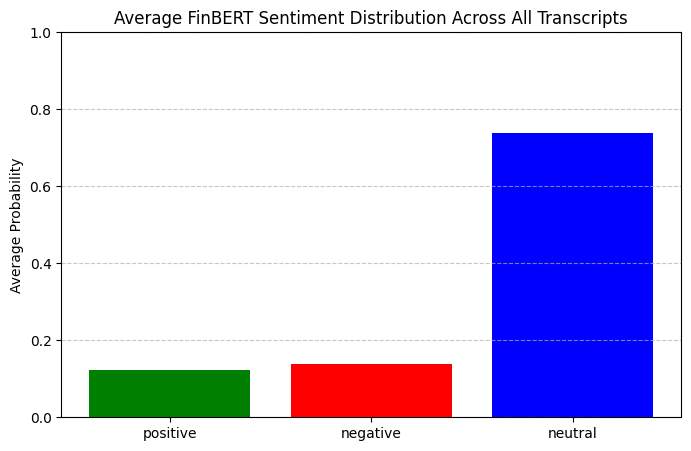


Average Sentiment Probabilities Across All Transcripts:
Positive: 0.122
Negative: 0.139
Neutral: 0.739


In [ ]:
# Redefine the analyze_and_visualize_sentiment function to return probabilities
def analyze_and_visualize_sentiment(text, max_length=512): # FinBERT max_length can only be 512
    # Tokenize the text with truncation and padding
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding="max_length", max_length=max_length)

    # Move inputs to the same device as the model
    device = model.device
    inputs = {key: val.to(device) for key, val in inputs.items()}


    # Get model outputs
    with torch.no_grad(): # Use no_grad as we are not training
      outputs = model(**inputs)

    # Get probabilities
    probabilities = torch.softmax(outputs.logits, dim=1)[0]
    probs = probabilities.detach().cpu().numpy() # Move probabilities to CPU before converting to numpy

    # Return probabilities
    return probs

# Define label mapping (FinBERT: 0=positive, 1=negative, 2=neutral)
label_mapping = {0: "positive", 1: "negative", 2: "neutral"}
labels = [label_mapping[i] for i in range(3)]

# List to store sentiment probabilities for all transcripts
all_probs = []

# Analyze sentiment for each transcript and store probabilities
print("Analyzing sentiment for all transcripts...")
for i, transcript_text in enumerate(tqdm(all_transcripts_list, desc="Analyzing transcripts")):
    probs = analyze_and_visualize_sentiment(transcript_text)
    all_probs.append(probs)

# Convert the list of probabilities to a NumPy array for easier aggregation
all_probs_array = np.array(all_probs)

# Calculate the average probabilities across all transcripts
average_probs = np.mean(all_probs_array, axis=0)

# Visualize the average sentiment distribution using a bar plot
plt.figure(figsize=(8, 5))
plt.bar(labels, average_probs, color=['green', 'red', 'blue'])
plt.ylabel('Average Probability')
plt.title('Average FinBERT Sentiment Distribution Across All Transcripts')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Print the average probabilities
print("\nAverage Sentiment Probabilities Across All Transcripts:")
for label, avg_prob in zip(labels, average_probs):
    print(f"{label.capitalize()}: {avg_prob:.3f}")

Where JPMorgan was more positive than negative, Credit Suisse data was more negative than positive as it approached collapse.

**FinBERT - tone analyser**

In [ ]:
# Load FinBERT model and tokenizer
model_name = "yiyanghkust/finbert-tone"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

# Function to get sentiment score for each token
def get_token_sentiments(text):
    tokens = text.split()
    negative_tokens = []

    for i, token in enumerate(tokens):
        input_text = ' '.join(tokens[max(i - 2, 0): i + 3])  # Use a sliding window
        inputs = tokenizer(input_text, return_tensors="pt", truncation=True)
        with torch.no_grad():
            outputs = model(**inputs)
            scores = torch.nn.functional.softmax(outputs.logits, dim=-1)
            label = torch.argmax(scores).item()
            label_str = model.config.id2label[label]

            if label_str.lower() == 'negative':
                negative_tokens.append((token, scores[0][label].item()))

    return negative_tokens

# Check with example usage
text = "The company suffered huge losses but expects a strong recovery."
negative_words = get_token_sentiments(text)

# Print negative tokens and their confidence scores
for word, score in negative_words:
    print(f"Negative word: {word} (confidence: {score:.2f})")

config.json:   0%|          | 0.00/533 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/226k [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/439M [00:00<?, ?B/s]

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


Negative word: The (confidence: 1.00)
Negative word: company (confidence: 1.00)
Negative word: suffered (confidence: 1.00)
Negative word: huge (confidence: 1.00)
Negative word: but (confidence: 0.97)


Model output was not accurate and so the model was adjusted to produce accurate output.

In [ ]:
# Check label integers
model.config.id2label

{0: 'Neutral', 1: 'Positive', 2: 'Negative'}

In [ ]:
# Reverse integers so they make more sense (0: 'Negative', 1: 'Positive', 2: 'Neutral')
label2id = {v.lower(): k for k, v in model.config.id2label.items()}

In [ ]:
# Prepare inputs for the model
inputs = tokenizer(text, return_tensors="pt", truncation=True) # Use the text variable defined earlier

# Get model outputs
with torch.no_grad(): # Use no_grad as not training
    outputs = model(**inputs)

# Calculate scores using the newly defined outputs
scores = torch.nn.functional.softmax(outputs.logits, dim=-1)
negative_score = scores[0][label2id['negative']].item()

print(f"Negative score: {negative_score}") # Print the score to verify

Negative score: 0.12080474197864532


This was a sensible score for the test sentence, and so the model was then run on the transcript data.

In [ ]:
batch_size = 128 # Run in batched to reduce use of RAM
data = []

# Loop through batches
for i in tqdm(range(0, len(CS_df_sentences), batch_size), desc="Scoring sentences"):
    batch_sentences = CS_df_sentences.iloc[i:i+batch_size]

    inputs = tokenizer(
        batch_sentences["sentence"].tolist(),
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=512
    )

    with torch.no_grad():
        outputs = model(**inputs)

    scores = torch.nn.functional.softmax(outputs.logits, dim=-1)

    for j, s in enumerate(scores):
        data.append({
            "quarter": batch_sentences.iloc[j]["quarter"],
            "year": batch_sentences.iloc[j]["year"],
            "document_type": batch_sentences.iloc[j]["document_type"],
            "sentence": batch_sentences.iloc[j]["sentence"],
            "negative_score": s[label2id['negative']].item(),
            "neutral_score": s[label2id['neutral']].item(),
            "positive_score": s[label2id['positive']].item()
        })

# Create final DataFrame
CS_df_sentences = pd.DataFrame(data)
print(CS_df_sentences.head())

Scoring sentences: 100%|██████████| 207/207 [1:28:02<00:00, 25.52s/it]

  quarter  year     document_type  \
0      Q1  2021  Earnings Release   
1      Q1  2021  Earnings Release   
2      Q1  2021  Earnings Release   
3      Q1  2021  Earnings Release   
4      Q1  2021  Earnings Release   

                                            sentence  negative_score  \
0  Key metrics in / end of % change in / end of %...    2.696828e-06   
1  Net revenues 4,582 5,437 5,221 (16) (12) 22,69...    6.228421e-05   
2  Assets under management 1,614.0 1,623.0 1,511....    8.708237e-06   
3  Total shareholders’ equity 44,032 44,498 42,67...    5.552895e-07   
4  2 Credit Suisse In 4Q21, we recorded a net los...    9.961908e-01   

   neutral_score  positive_score  
0       0.999990    7.309530e-06  
1       0.999916    2.160955e-05  
2       0.999982    9.329816e-06  
3       0.999999    4.769465e-07  
4       0.003805    4.629287e-06  


In [ ]:
# Extract all sentences with negative score greater than 0.05
# Change JPM_df to JPM_df_sentences to access the sentiment scores
negative_sentences_df = CS_df_sentences[CS_df_sentences['negative_score'] > 0.05]

# Display the filtered DataFrame
print(negative_sentences_df)

      quarter  year     document_type  \
4          Q1  2021  Earnings Release   
21         Q1  2021  Earnings Release   
22         Q1  2021  Earnings Release   
25         Q1  2021  Earnings Release   
26         Q1  2021  Earnings Release   
...       ...   ...               ...   
26023    None  2022  Financial Report   
26196    None  2022  Financial Report   
26381    None  2022  Financial Report   
26387    None  2022  Financial Report   
26394    None  2022  Financial Report   

                                                sentence  negative_score  \
4      2 Credit Suisse In 4Q21, we recorded a net los...        0.996191   
21     Results summary 4Q21 results In 4Q21, Credit S...        0.127178   
22     In 4Q21, Credit Suisse reported a loss before ...        0.943769   
25     2021 results In 2021, Credit Suisse reported a...        0.168659   
26     In 2021, Credit Suisse reported a loss before ...        0.977054   
...                                                

In [ ]:
# Export negative_sentences_df into a csv
negative_sentences_df.to_csv('negative_sentences_df.csv', index=False)

In [ ]:
# Filter positive sentences with score > 0.05
positive_sentences_df_subset = CS_df_sentences[CS_df_sentences['positive_score'] > 0.05][['sentence', 'positive_score']]

# Sort for better viewing
positive_sentences_df_subset = positive_sentences_df_subset.sort_values(by='positive_score', ascending=False)

# Display neatly in the console
print(positive_sentences_df_subset.to_string(index=False))

In [ ]:
# Export positive sentences as a csv
positive_sentences_df_subset.to_csv('positive_sentences_df_subset.csv', index=False)

**Manual validation**

*   Geopolitical tensions correctly identified in correct quarter: "Equities
    declined by 5% in 1Q22, driven by geopolitical tensions, accelerating inflation, central banks increasing rates and fears of a macroeconomic slowdown."
*   Poor financial resilience and organisational resilience correctly
    identified throughout the analysis: "Negative net revenues of CHF 173 million in 1Q22 were primarily driven by negative treasury results."
*   Issues with fraud indicated in mentioning of "asset resolution unit" in
    negative sentences: "We reported negative net revenues of CHF 153 million in 2021, primarily driven by negative treasury results and the Asset Resolution Unit."
*   Summary: "The year 2021 was very disappointing and challenging for Credit
    Suisse"

In [ ]:
# Separate out all negative results from "analysts"
# Change negative_sentences_df_subset to the correct DataFrame JPM_df_sentences
negative_sentences_df_subset_analyst = negative_sentences_df[negative_sentences_df['sentence'].str.contains('analyst', case=False)]

# Show DataFrame
print(negative_sentences_df_subset_analyst)

# Give shape of negative analyst DataFrame
negative_sentences_df_subset_analyst.shape

Empty DataFrame
Columns: [quarter, year, document_type, sentence, negative_score, neutral_score, positive_score]
Index: []


(0, 7)

In [ ]:
# Separate out all positive results from "analysts"
# Change positive_sentences_df_subset to the correct DataFrame JPM_df_sentences
positive_sentences_df_subset_analyst = positive_sentences_df_subset[positive_sentences_df_subset['sentence'].str.contains('analyst', case=False)]

# Show DataFrame
print(positive_sentences_df_subset_analyst)

                                                sentence  positive_score
903    Joined the Net-Zero Banking Alliance (NZBA) an...        0.999959
3461   Management believes that these metrics are mea...        0.054197
23782  Management believes that these metrics are mea...        0.054197
1109   Management believes that these metrics are mea...        0.054197
24697  Management believes that tangible shareholders...        0.051149


There was little direct analyst speak picked up in the documents making this form of analysis irrelevant with this model.

**Prompting FinBERT**

FinBERT was prompted to stress-test it in the run up to Credit Suisse collapse in March 2023.


--- Topic: Financial Stress ---
Analyzing 3 sentences related to 'Financial Stress'...


Analyzing sentences for 'Financial Stress': 100%|██████████| 3/3 [00:00<00:00,  3.49it/s]


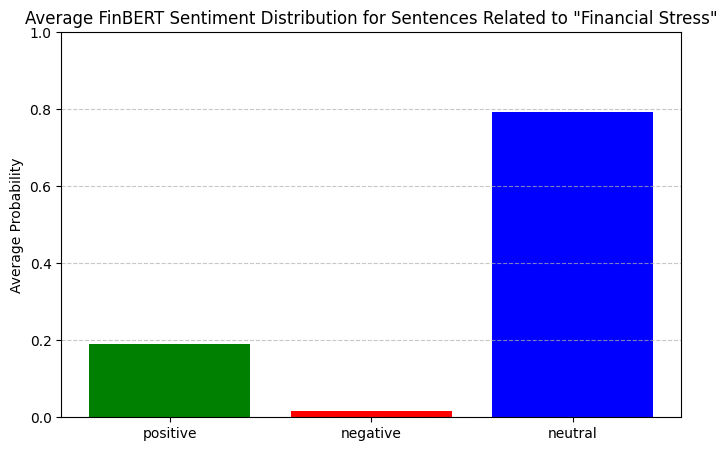


Average Sentiment Probabilities for Sentences Related to 'Financial Stress':
Positive: 0.191
Negative: 0.017
Neutral: 0.792

--- Topic: Fraud ---
Analyzing 47 sentences related to 'Fraud'...


Analyzing sentences for 'Fraud': 100%|██████████| 47/47 [00:12<00:00,  3.91it/s]


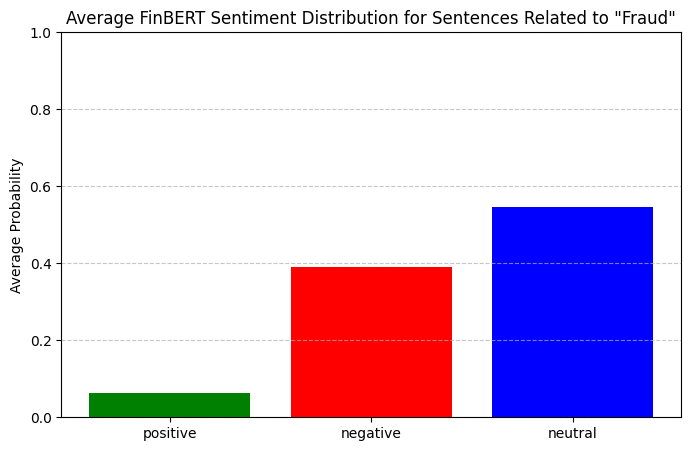


Average Sentiment Probabilities for Sentences Related to 'Fraud':
Positive: 0.064
Negative: 0.389
Neutral: 0.547

--- Topic: Losses ---
Analyzing 2021 sentences related to 'Losses'...


Analyzing sentences for 'Losses': 100%|██████████| 2021/2021 [07:54<00:00,  4.26it/s]


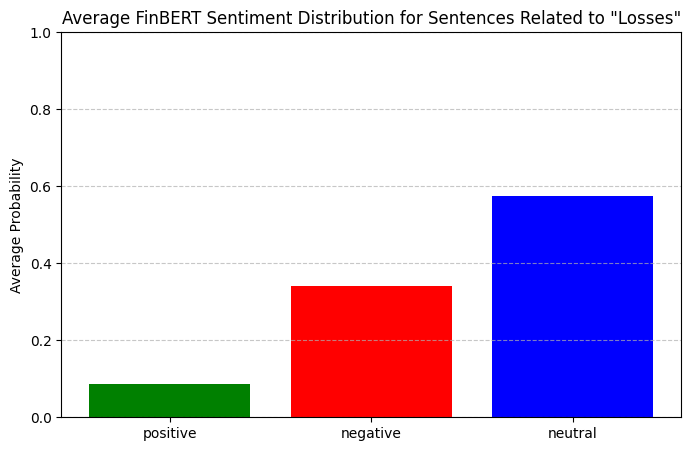


Average Sentiment Probabilities for Sentences Related to 'Losses':
Positive: 0.087
Negative: 0.340
Neutral: 0.574

--- Topic: Leadership Changes ---
No sentences found related to 'Leadership Changes'.

--- Topic: Mergers ---
Analyzing 22 sentences related to 'Mergers'...


Analyzing sentences for 'Mergers': 100%|██████████| 22/22 [00:04<00:00,  4.80it/s]


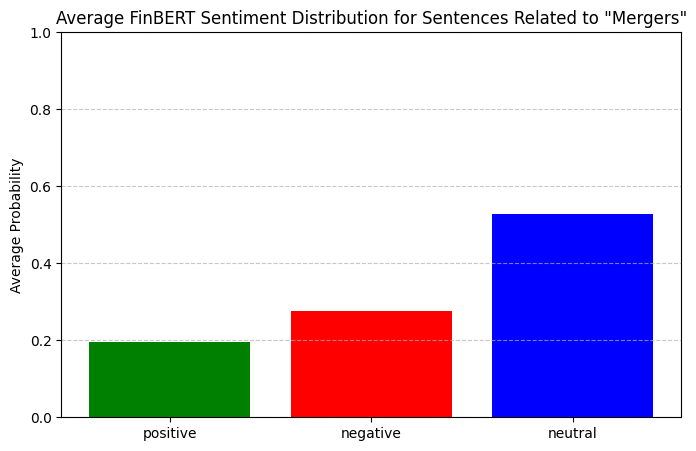


Average Sentiment Probabilities for Sentences Related to 'Mergers':
Positive: 0.196
Negative: 0.275
Neutral: 0.529


In [ ]:
# Define the analyze_and_visualize_sentiment function to return probabilities
def analyze_and_visualize_sentiment(text, max_length=512): # FinBERT max_length can only be 512
    # Tokenize the text with truncation and padding
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding="max_length", max_length=max_length)

    # Move inputs to the same device as the model
    device = model.device
    inputs = {key: val.to(device) for key, val in inputs.items()}


    # Get model outputs
    with torch.no_grad(): # Use no_grad as we are not training
      outputs = model(**inputs)

    # Get probabilities
    probabilities = torch.softmax(outputs.logits, dim=1)[0]
    probs = probabilities.detach().cpu().numpy() # Move probabilities to CPU before converting to numpy

    # Return probabilities
    return probs

topics = {
    "Financial Stress": "The ongoing war in Ukraine has severely disrupted markets, leading to increased volatility and widespread financial stress across sectors.",
    "Fraud": "A major fraud scandal has shattered investor trust and triggered regulatory investigations, further eroding confidence in the market.",
    "Losses": "The significant net losses reported this quarter highlight the bank's persistent risk mismanagement and operational inefficiencies.",
    "Leadership Changes": "Sudden leadership changes have led to strategic confusion and deepened investor concerns over long-term stability.",
    "Mergers": "The upcoming mergers are being driven by financial distress and market pressures, raising fears of layoffs and reduced competitiveness."
}

# Define label mapping (FinBERT: 0=positive, 1=negative, 2=neutral)
label_mapping = {0: "positive", 1: "negative", 2: "neutral"}
labels = [label_mapping[i] for i in range(3)]

# Analyze each topic and plot sentiment using sentences from CS_df_sentences
for topic, prompt in topics.items():
    print(f"\n--- Topic: {topic} ---")

    # Filter sentences that contain keywords related to the topic
    topic_sentences_df = CS_df_sentences[CS_df_sentences['sentence'].str.contains(topic, case=False, na=False)]

    if not topic_sentences_df.empty:
        print(f"Analyzing {len(topic_sentences_df)} sentences related to '{topic}'...")
        all_probs = []
        # Analyze sentiment for each sentence in the filtered DataFrame
        for index, row in tqdm(topic_sentences_df.iterrows(), total=len(topic_sentences_df), desc=f"Analyzing sentences for '{topic}'"):
            probs = analyze_and_visualize_sentiment(row['sentence'])
            all_probs.append(probs)

        # Convert the list of probabilities to a NumPy array for easier aggregation
        all_probs_array = np.array(all_probs)

        # Calculate the average probabilities across all relevant sentences
        average_probs = np.mean(all_probs_array, axis=0)

        # Visualize the average sentiment distribution using a bar plot
        plt.figure(figsize=(8, 5))
        plt.bar(labels, average_probs, color=['green', 'red', 'blue'])
        plt.ylabel('Average Probability')
        plt.title(f'Average FinBERT Sentiment Distribution for Sentences Related to "{topic}"')
        plt.ylim(0, 1)
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.show()

        # Print the average probabilities
        print(f"\nAverage Sentiment Probabilities for Sentences Related to '{topic}':")
        for label, avg_prob in zip(labels, average_probs):
            print(f"{label.capitalize()}: {avg_prob:.3f}")
    else:
        print(f"No sentences found related to '{topic}'.")

All of the stressors, except one (Financial Stress), were correctly identified as negative. This included the likelihood of mergers where JPMorgan had shown this to be positive. This is correct for each bank; for JPMorgan the mergers were a positive occurence whereas for Credit Suisse merging was indicative of likely collapse.

**Phi-3-mini-4k-instruct**

Given the predicition of forthcoming collapse by the models up to this point, the output of the sentence analyser was fed through Phi-3 to see if it could produce actionable regulatory insights.

In [ ]:
# Convert negative_sentences_df into a list
negative_sentences = negative_sentences_df['sentence'].tolist()

In [ ]:
# Convert negative_sentences into an array
negative_sentences_array = np.array(negative_sentences)

In [ ]:
# Set random seed to prevent inherent variability
torch.random.manual_seed(0)

In [ ]:
# Load model
model = AutoModelForCausalLM.from_pretrained(
    "microsoft/Phi-3-mini-4k-instruct",
    torch_dtype="auto",
    trust_remote_code=True,
)
tokenizer = AutoTokenizer.from_pretrained("microsoft/Phi-3-mini-4k-instruct")

<frozen importlib._bootstrap>:283: DeprecationWarning: the load_module() method is deprecated and slated for removal in Python 3.12; use exec_module() instead
<frozen importlib._bootstrap>:283: DeprecationWarning: the load_module() method is deprecated and slated for removal in Python 3.12; use exec_module() instead


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.44k [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.94M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/306 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/599 [00:00<?, ?B/s]

Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


In [ ]:
# Produce pipeline
pipe = pipeline(
    "text-generation",
    model=model,
    tokenizer=tokenizer,
)

In [ ]:
# Configure the behaviour of text generation
generation_args = {
    "max_new_tokens": 500,
    "return_full_text": False,
    "temperature": 0.7,
    "do_sample": False,
}

In [ ]:
# Prompts
messages = [
    {
        "role": "system",
        "content": "You are a data analyst at a large bank. Your role is to identify and summarize financial and operational risks using structured insights. Present your findings in a numbered list format, focusing on risks that impact governance, financial resilience, operational stability, and regulatory compliance."
    },
    {
        "role": "user",
        "content": "Here is a list of key topics extracted from quarterly bank reviews: ['war', 'loss', 'fraud', 'financial stress']. Please group or compress these topics into a concise, numbered list of risk categories relevant to financial and operational stability."
    },
    {
        "role": "assistant",
        "content": "1. Governance and Oversight: Strengthen internal controls and board accountability to mitigate governance failures.\n2. Data Security and Integrity: Address vulnerabilities in data systems that could lead to breaches or financial misstatements.\n3. Financial Resilience: Monitor capital adequacy and stress test scenarios to maintain liquidity under adverse conditions.\n4. Operational Resilience: Improve business continuity planning and disaster recovery to reduce downtime during disruptions."
    },
    {
        "role": "user",
        "content": f"Here is a new list of key themes extracted from internal reports: {negative_sentences_array}. Please group or compress the topics and return a numbered list of actionable risk insights relevant to the banking sector."
    }
]

In [ ]:
# Acquire output
output = pipe(messages, **generation_args)

#print(sequences[0]['generated_text'])
insights = output[0]['generated_text']

In [ ]:
print(insights)

 1. Legal and Regulatory Risks:

   - Prepare for potential litigation by reviewing and updating legal strategies and insurance coverage.
   - Conduct a thorough risk assessment of client relationships to identify and mitigate potential disputes.
   - Ensure compliance with all regulatory requirements to avoid sanctions and fines.

2. Financial Reporting Risks:

   - Enhance the accuracy and reliability of financial reporting by implementing robust internal controls and audit processes.
   - Regularly review and update the bank's accounting policies to reflect current standards and best practices.
   - Provide comprehensive training to finance staff on the preparation and disclosure of financial statements.

3. Forward-Looking Statements Risks:

   - Develop a clear communication strategy to manage expectations regarding forward-looking statements.
   - Establish a monitoring system to track the progress of initiatives and adjust plans as necessary.
   - Create a contingency plan to ad

Phi provided greater, and more intuitive, insight than FinBERT alone:-

1. Phi also picked up on the issues with fraud seen in the run up to the Credit Suisse collapse.

2. Phi intuitively, picked up on possible inaccuracies in reporting it is less possible to visualise with FinBERT without manual validation.

3. Phi indicated that there should have been an internal system to track the performance of strategic initiatives — like restructuring, risk management reforms, or liquidity improvements — and make timely course corrections. Credit Suisse failed to effectively monitor and pivot when strategic efforts (e.g., cost-cutting, de-risking) underperformed or failed, leading to compounded issues like liquidity strain and loss of investor trust.

4. When forecasts or goals started to go off track, there should have been back-up strategies ready — like capital injections, divestitures, or emergency liquidity measures. Credit Suisse lacked sufficient contingency planning or failed to execute them effectively, which left the bank vulnerable to shocks (e.g. client withdrawals, market pressure) that rapidly spiraled into a crisis.

**Comparison of JPMorgan and Credit Suisse results**

ProsusAI/finbert: This recognised more positive than negative sentiment for JPM in the quarters analysed but more negative sentiment than positive for CS, as would be expected. However, much of the content was neutral.

Sentiment Intensity Analyzer (SIA): SIA picked up ten times more “losses” in these transcripts for CS than JPM. Both identified “war”, “debt”, and “recession” as top-negative words and therefore these topics were the focus for manual validation using financial and global news. For CS, "fraud" was picked up as a key negative word. This was one of the key themes responsible for the collapse of CS and was therefore used in prompt engineering.

The FinBERT tone analyser “yiyanghkust/finbert-tone”: Manual validation showed "negative" sentences from the JPMorgan trsncripts clearly related to data risk, financial resilience and operational resilience. Negative sentiment was ranked appropriately. The analysis had picked up difficulties associated with the war in Ukraine and relationships with China, admittance of risk by an executive, and negative financial prediction. All were manually validated to occur in appropriate quarters. It also correctly classified, with appropriate rank, neutral, and positive, material which would perhaps be difficult to classify. This would be useful for PRA analysts in instigating regulatory actions to mitigate risk. For CS, notably, it picked up poor financial and organisational resilience throughout the analysis, including issues with fraud (asset resolution) in the appropriate time line.

Prompting FinBERT: The accuracy of classification, using manual validation, was approximately 80-90%, in accordance with the literature. Pertinently, it correctly associated forthcoming mergers for CS as negative and for JPM as positive in appropriate quarters.

Phi: Phi produced some high-quality return relating to legal and regulatory risks (pertaining to the issues with fraud), and financial reporting risks (pertaining to masking of information relating to the bank’s solvency).


**Conclusion**

The BoE uses these tools on a daily basis and they have shown to be swift, insightful, and impactful at times, as shown here. However, accuracy is only 80-90% with the best models and false negatives occur. When tested on a section of more recent Q1 2025 text, they lacked the ability to delve deep into subtle nuances seen in multi-modal small text which could better warn of and predict financial risk.

**Future scalability**

Were FinBERT and Phi to be used it would be recommended to use a cloud-based infrastructure, for example, such as Azure. This would enable the on-demand scalability and resource allocation needed for handling the diverse computational demands of multiple firms.

**References**

Genc (2020) FinBERT: Financial Sentiment Analysis with BERT. *Medium* Available at: https://medium.com/prosus-ai-tech-blog/finbert-financial-sentiment-analysis-with-bert-b277a3607101 (Accessed 02/06/25)

Huang, H.A., Wang, H. and Yang, Y (2022) FinBERT: A Large Language Model for Extracting Information from Financial Text. Contemporary Accounting Research. Available at: https://onlinelibrary.wiley.com/doi/10.1111/1911-3846.12832 (Accessed 10/06/25)

Kim, W., Sporer, J., Lee, C.L. and Handschuch, S. (2024) Is Small Really Beautiful for Central Bank Communication? Evaluating Language Models for Finance: Llama-3-70B, GPT-4, FinBERT-FOMC, FinBERT, and VADER. ACM Digital Library. Available at: https://dl.acm.org/doi/fullHtml/10.1145/3677052.3698675  (Accessed 05/06/24)

Rahultiwari (2024) Unlocking the Power of Sentence Embeddings with all-MiniLM-L6-v2. *Medium*. Available at: https://medium.com/@rahultiwari065/unlocking-the-power-of-sentence-embeddings-with-all-minilm-l6-v2-7d6589a5f0aa (Accessed 26/06/25)

Sener, B. (2023) Sentiment Analysis for Financial News with Transformers. Medium. Available at: https://medium.com/@batuhansenerr/sentiment-analysis-for-financial-news-with-transformers-88ba9ead4de3 (Accessed 11/06/25)

Singh, S. (2024) Innovative Sentiment Analysis: Better Than NLTK, TextBlob, and Even LLMs! *Medium* Available at: https://medium.com/@simranjeetsingh1497/innovative-sentiment-analysis-better-than-nltk-textblob-and-even-llms-baa37b1936e2 (Accessed 04/06/25)